# The Global Digital Divide
**Question:**: Has internet access grown equally across countries, or are some countries, espeically lower-income ones, being left behind?


In [88]:
   import pandas as pd

   # Share of the population using the Internet
   # Source: ITU via World Bank, processed by Our World in Data. Licence: CC BY 4.0
   url = "https://ourworldindata.org/grapher/share-of-individuals-using-the-internet.csv?v=1&csvType=full&useColumnShortNames=false"
   df = pd.read_csv(url, storage_options={"User-Agent": "Our World In Data data fetch/1.0"})

In [89]:
df.head()

,Entity,Code,Year,Share of the population using the Internet
0,Afghanistan,AFG,1990,0.000000
1,Afghanistan,AFG,2001,0.004723
2,Afghanistan,AFG,2002,0.004561
3,Afghanistan,AFG,2003,0.087891
4,Afghanistan,AFG,2004,0.105809


In [90]:
df.columns

Index(['Entity', 'Code', 'Year', 'Share of the population using the Internet'], dtype='object')

In [91]:
# Rename the 4th column to something short and clear
df = df.rename(columns={df.columns[3]: "Internet Use (%)"})
df.head()

,Entity,Code,Year,Internet Use (%)
0,Afghanistan,AFG,1990,0.000000
1,Afghanistan,AFG,2001,0.004723
2,Afghanistan,AFG,2002,0.004561
3,Afghanistan,AFG,2003,0.087891
4,Afghanistan,AFG,2004,0.105809


In [92]:
df.shape

(6476, 4)

In [93]:
df["Code"].isnull().sum()

np.int64(0)

In [94]:
df[df["Code"].isnull()]["Entity"].unique()

array([], dtype=object)

In [95]:
df[df["Code"].str.len() != 3]["Entity"].unique()

array(['East Asia and Pacific (WB)', 'Europe and Central Asia (WB)',
       'High-income countries', 'Kosovo',
       'Latin America and Caribbean (WB)', 'Low-income countries',
       'Lower-middle-income countries',
       'Middle East, North Africa, Afghanistan and Pakistan (WB)',
       'North America (WB)', 'South Asia (WB)', 'Sub-Saharan Africa (WB)',
       'Upper-middle-income countries', 'World'], dtype=object)

In [96]:
df["Entity"].nunique()

225

In [97]:
# Table 1: the four World Bank income groups
income_groups = ["Low-income countries", "Lower-middle-income countries", "Upper-middle-income countries", "High-income countries"]

df_income = df[df["Entity"].isin(income_groups)].copy()
df_income["Entity"].value_counts()

,count
Entity,
High-income countries,21
Low-income countries,21
Lower-middle-income countries,21
Upper-middle-income countries,21


In [98]:
# Table 2: real countires only (3-letter codes, plus Kosovo)
is_country =(df["Code"].str.len() == 3) | (df["Entity"] == "Kosovo")
df_countries = df[is_country].copy()
df_countries["Entity"].nunique()

213

In [99]:
# Rearrange: one row per year, one column per income group
income_wide = df_income.pivot(index="Year", columns="Entity", values="Internet Use (%)")
income_wide = income_wide[income_groups]
income_wide.tail()

Entity,Low-income countries,Lower-middle-income countries,Upper-middle-income countries,High-income countries
Year,,,,
2021,19.0,47.4,79.4,90.0
2022,21.2,52.3,82.7,91.0
2023,22.0,55.4,85.3,91.9
2024,22.5,58.9,86.9,93.0
2025,23.4,62.9,88.8,94.2


<function matplotlib.pyplot.show(close=None, block=None)>

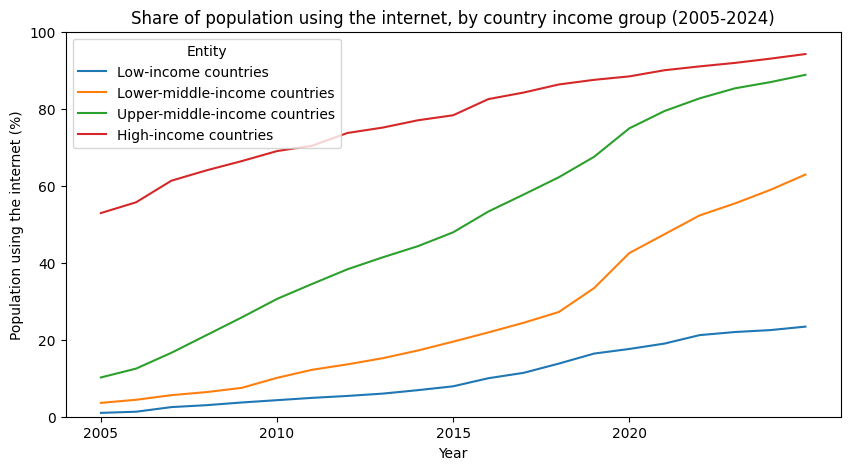

In [100]:
import matplotlib.pyplot as plt
import os
os.makedirs("images", exist_ok=True)

income_wide.plot(figsize=(10,5))
plt.title("Share of population using the internet, by country income group (2005-2024)")
plt.xlabel("Year")
plt.ylabel("Population using the internet (%)")
plt.ylim(0,100)
plt.xticks(range(2005, 2025, 5))
plt.savefig("images/income_groups_over_time.png", dpi=150, bbox_inches="tight")
plt.show

In [101]:
   # Gap between high-income and low-income groups, in percentage points
   income_wide["Gap"] = income_wide["High-income countries"] - income_wide["Low-income countries"]
   income_wide.loc[[ 2005, 2010, 2015, 2020, 2024], "Gap"]

,Gap
Year,
2005,51.9
2010,64.7
2015,70.4
2020,70.8
2024,70.5


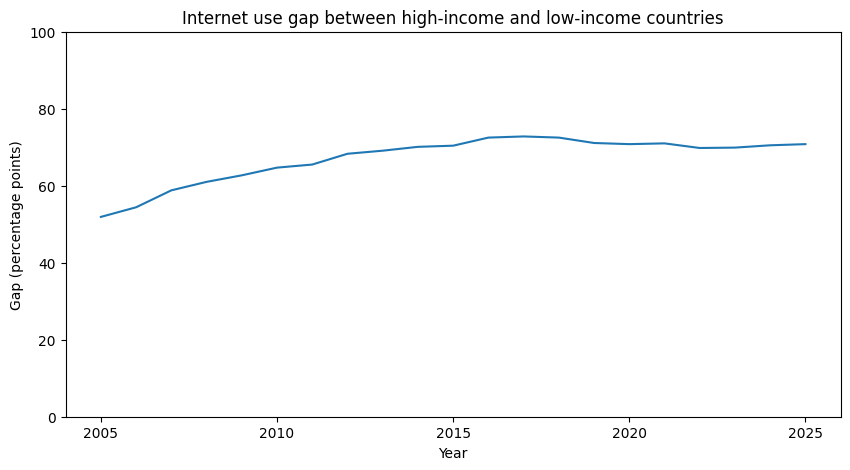

In [102]:
income_wide["Gap"].plot(figsize=(10,5))
plt.title("Internet use gap between high-income and low-income countries")
plt.xlabel("Year")
plt.ylabel("Gap (percentage points)")
plt.ylim(0,100)
plt.xticks(range(2005, 2026, 5))
plt.savefig("images/income_gap.png", dpi=150, bbox_inches="tight")
plt.show()

In [103]:
# Internet use (%) in each income group, every 10 years
income_wide.loc[[2005, 2015, 2025]].round(1)

Entity,Low-income countries,Lower-middle-income countries,Upper-middle-income countries,High-income countries,Gap
Year,,,,,
2005,1.0,3.6,10.2,52.9,51.9
2015,7.9,19.5,47.9,78.3,70.4
2025,23.4,62.9,88.8,94.2,70.8


In [104]:
df_countries[df_countries["Entity"] == "North Korea"]

,Entity,Code,Year,Internet Use (%)
4373,North Korea,PRK,1990,0.0
4374,North Korea,PRK,1997,0.0
4375,North Korea,PRK,1998,0.0
4376,North Korea,PRK,1999,0.0
4377,North Korea,PRK,2000,0.0
4378,North Korea,PRK,2001,0.0
4379,North Korea,PRK,2002,0.0
4380,North Korea,PRK,2003,0.0
4381,North Korea,PRK,2004,0.0


In [105]:
df_countries[df_countries["Entity"] == "North Korea"].tail(10)

,Entity,Code,Year,Internet Use (%)
4373,North Korea,PRK,1990,0.0
4374,North Korea,PRK,1997,0.0
4375,North Korea,PRK,1998,0.0
4376,North Korea,PRK,1999,0.0
4377,North Korea,PRK,2000,0.0
4378,North Korea,PRK,2001,0.0
4379,North Korea,PRK,2002,0.0
4380,North Korea,PRK,2003,0.0
4381,North Korea,PRK,2004,0.0


In [106]:
   # How many countries have data for the most recent years?
   for year in [2020, 2023, 2024, 2025]:
       count = df_countries[df_countries["Year"] == year]["Entity"].nunique()
       print(year, ":", count, "countries out of 213")

2020 : 184 countries out of 213
2023 : 181 countries out of 213
2024 : 182 countries out of 213
2025 : 10 countries out of 213


In [107]:
   # Stop at 2024: only 10 of 213 countries had reported data for 2025
   income_wide = income_wide[income_wide.index <= 2024]

In [108]:
   income_wide.loc[[2005, 2015, 2024]].round(1)

Entity,Low-income countries,Lower-middle-income countries,Upper-middle-income countries,High-income countries,Gap
Year,,,,,
2005,1.0,3.6,10.2,52.9,51.9
2015,7.9,19.5,47.9,78.3,70.4
2024,22.5,58.9,86.9,93.0,70.5


In [109]:
   # Exact internet use (%) for each group in 2024
   income_wide.loc[2024].round(1)

,2024
Entity,
Low-income countries,22.5
Lower-middle-income countries,58.9
Upper-middle-income countries,86.9
High-income countries,93.0
Gap,70.5


   ## Finding 1: The gap between rich and poor countries
   - In 2024, 93.0% of people in high-income countries used the internet, compared with 22.5% in low-income countries.
   - That means more than 3 in 4 people in low-income countries are still offline.
   - The gap grew from about 52 percentage points in 2005 to about 73 in 2016, then plateaued at around 70.
   - The gap levelling off may partly be a ceiling effect: high-income countries are close to 100%, so they have little room left to grow.
   - I used 2024 as the latest year, because only 10 of 213 countries had reported data for 2025.

In [110]:
   # How many percentage points did each group grow from 2014 to 2024?
   change = income_wide.loc[2024] - income_wide.loc[2014]
   change = change.drop("Gap").round(1)
   change

,0
Entity,
Low-income countries,15.6
Lower-middle-income countries,41.7
Upper-middle-income countries,42.6
High-income countries,16.0


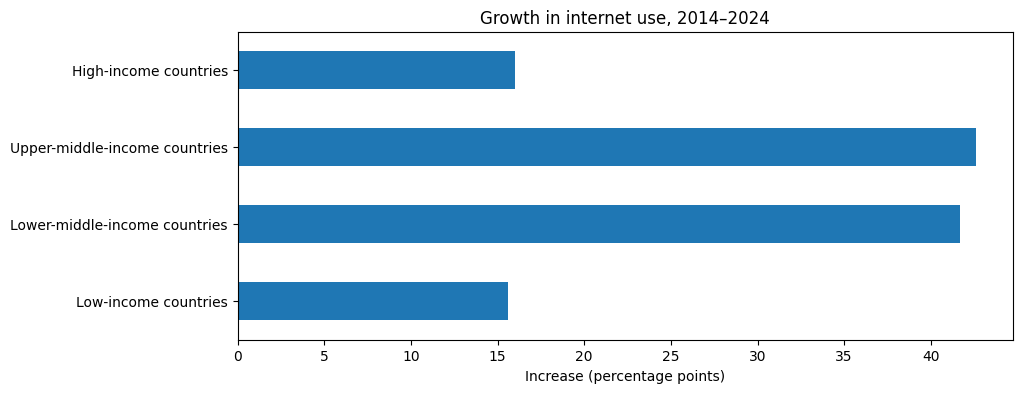

In [111]:
   change.plot(kind="barh", figsize=(10, 4))
   plt.title("Growth in internet use, 2014–2024")
   plt.xlabel("Increase (percentage points)")
   plt.ylabel("")
   plt.savefig("images/growth_2014_2024.png", dpi=150, bbox_inches="tight")
   plt.show()

## Finding 2: Middle-income countries are catchuping up, but low-income countries are not
- From 2014 to 2024, internet use grew by about 42 percentage points in both middle-income groups.
- Low-income countires grew by only 15.6 points, about the same as high-income countries (16.0 points), even though they had much more room to grow.
- This explains why the gap between high- and low-income countries stopped growing but did not shrink: both groups grew at a similar pace.
- i used percentage-point change, not percent change, because percent change makes small starting numbers look like huge progress.

In [112]:
   # World Bank income group for each country, each year
   # Source: World Bank, processed by Our World in Data. Licence: CC BY 4.0
   url2 = "https://ourworldindata.org/grapher/world-bank-income-groups.csv?v=1&csvType=full&useColumnShortNames=false"
   groups = pd.read_csv(url2, storage_options={"User-Agent": "Our World In Data data fetch/1.0"})
   groups.head()

,Entity,Code,Year,World Bank's income classification
0,Afghanistan,AFG,1987,Low-income countries
1,Afghanistan,AFG,1988,Low-income countries
2,Afghanistan,AFG,1989,Low-income countries
3,Afghanistan,AFG,1990,Low-income countries
4,Afghanistan,AFG,1991,Low-income countries


In [113]:
groups = groups.rename(columns={groups.columns[3]: "Income Group"})
groups["Income Group"].value_counts()


,count
Income Group,
High-income countries,2532
Lower-middle-income countries,2140
Low-income countries,1780
Upper-middle-income countries,1721


In [114]:
# keep only 2024, and only the columns we need
groups_2024 = groups[groups["Year"] == 2024][["Code", "Entity", "Income Group"]]
internet_2024 = df_countries[df_countries["Year"] == 2024][["Code", "Internet Use (%)"]]
print(len(groups_2024), "countries have an income group in 2024")
print(len(internet_2024), "countries have internet data in 2024")

218 countries have an income group in 2024
182 countries have internet data in 2024


In [115]:
# Join: start with every country that has an income group, then add its internet use
merged = groups_2024.merge(internet_2024, on="Code", how="left")
merged.head(10)

,Code,Entity,Income Group,Internet Use (%)
0,AFG,Afghanistan,Low-income countries,16.09500
1,ALB,Albania,Upper-middle-income countries,85.86390
2,DZA,Algeria,Upper-middle-income countries,77.41780
3,ASM,American Samoa,High-income countries,NaN
4,AND,Andorra,High-income countries,94.39760
5,AGO,Angola,Lower-middle-income countries,40.70480
6,ATG,Antigua and Barbuda,High-income countries,72.73040
7,ARG,Argentina,Upper-middle-income countries,89.66715
8,ARM,Armenia,Upper-middle-income countries,81.33930
9,ABW,Aruba,High-income countries,NaN


In [116]:
   # Which income groups are missing internet data in 2024?
   merged["Missing"] = merged["Internet Use (%)"].isnull()
   missing_count = merged.groupby("Income Group")["Missing"].sum()
   missing_share = (merged.groupby("Income Group")["Missing"].mean() * 100).round(1)
   print("Number of countries missing data:")
   print(missing_count)
   print()
   print("Percentage of countries missing data:")
   print(missing_share)

Number of countries missing data:
Income Group
High-income countries            23
Low-income countries              6
Lower-middle-income countries     4
Upper-middle-income countries     5
Name: Missing, dtype: int64

Percentage of countries missing data:
Income Group
High-income countries            25.8
Low-income countries             24.0
Lower-middle-income countries     8.0
Upper-middle-income countries     9.3
Name: Missing, dtype: float64


In [117]:
# List every country missng internet data in 2024, sorted by income group
missing_list = merged[merged["Missing"]][["Entity", "Income Group"]]
missing_list.sort_values("Income Group")

,Entity,Income Group
3,American Samoa,High-income countries
160,Puerto Rico,High-income countries
147,Northern Mariana Islands,High-income countries
140,New Caledonia,High-income countries
193,Taiwan,High-income countries
96,Isle of Man,High-income countries
81,Guam,High-income countries
79,Greenland,High-income countries
77,Gibraltar,High-income countries
167,Saint Martin (French part),High-income countries


## Finding 3: The least connected countries may be missing from the data
- In 2024, 36 of 218 countries with an incoem group had no internet data.
- By count, high-income (25.8%) and low-income (24%) groups had similar shares of mssing countries.
- But the missing high-income places were mostly small territories, while the missing low-income countires were Syria, Sudan, South Sudan, Yeman, North Korea and Eritrea: countries affected by conflict or with tightly controlled communication.
- These countries are home to well over 100 million people, who are likely among the least connected in the world. This means the low-income average (22.5%) may ake the digital divide look smaller than it really is